<a href="https://colab.research.google.com/github/iqraimtiaz1804/scipy-python-google-colab-practical/blob/main/SciPy_Complete_Practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SciPy Library — Complete Practical Demonstration

**Course practical:** Scientific computing with Python in Google Colab
**Student:** *Iqra Imtiaz*
**Date:** *26-OCT-2026*

**What this notebook covers**

| # | Section |
|---|---------|
| 1 | Title |
| 2 | Introduction to SciPy |
| 3 | Installation and Setup |
| 4 | Required Libraries |
| 5 | SciPy Cluster (`scipy.cluster`) |
| 6 | SciPy Constants (`scipy.constants`) |
| 7 | SciPy FFTPACK (`scipy.fftpack`) |
| 8 | SciPy Interpolation (`scipy.interpolate`) |
| 9 | SciPy Linear Algebra (`scipy.linalg`) |
| 10 | SciPy NDIMAGE (`scipy.ndimage`) |
| 11 | Summary Table |
| 12 | Real-World Applications |
| 13 | Conclusion |

**How to use:** run the cells from top to bottom (**Runtime → Run all**). Every example uses small built-in sample data, so no files or internet downloads are needed.

# 2. Introduction to SciPy

### 2.1 What is SciPy?
SciPy is a free, open-source Python library for **scientific and technical computing**. It gives us ready-made, well-tested tools for maths, science and engineering, so we do not have to write difficult algorithms from scratch.

*Real-life example:* NumPy is like a kitchen with good knives and pots. SciPy is like a set of ready-made recipe tools (a rice cooker, a blender, an oven) built on top of that kitchen.

### 2.2 What does SciPy stand for?
**SciPy = Scientific Python.**

### 2.3 Why do we use SciPy?
- It saves time: one function call can replace pages of maths code.
- The code inside is fast, because the heavy work is done in compiled C, C++ and Fortran.
- It is trusted: scientists, engineers and companies use it every day.

### 2.4 What is scientific computing?
Scientific computing means using computers to solve science and engineering problems with numbers: for example, finding the frequency of a sound, estimating a missing temperature reading, solving equations, or processing an image.

### 2.5 How is SciPy different from NumPy?

| NumPy | SciPy |
|---|---|
| Gives us the **array** (a fast table of numbers) and basic maths on arrays | Gives us **advanced tools** that work on those arrays |
| Examples: `np.array`, `np.mean`, `np.sin` | Examples: clustering, FFT, interpolation, linear algebra, image filters |
| The foundation | The building built on the foundation |

### 2.6 How does SciPy use NumPy arrays?
SciPy functions take NumPy arrays as input and give NumPy arrays back. So you create your data with NumPy, pass it to SciPy, and plot the result with Matplotlib. You will see this pattern in every module below.

### 2.7 What are SciPy subpackages (modules)?
SciPy is organised into **subpackages**. Each one is a toolbox for one type of problem. In this practical we study six:

| Subpackage | Toolbox for |
|---|---|
| `scipy.cluster` | Grouping similar data |
| `scipy.constants` | Scientific constants (speed of light, etc.) |
| `scipy.fftpack` | Fourier transforms (frequency analysis) |
| `scipy.interpolate` | Estimating values between known points |
| `scipy.linalg` | Matrices and linear algebra |
| `scipy.ndimage` | Image processing |

### 2.8 Real-world applications (short list)
Audio and music analysis, medical image processing, weather and sensor data, engineering simulations, data science and machine learning, physics and chemistry calculations. A fuller list is in Section 12.

### 2.9 Why is SciPy useful for Software Engineering, AI and Data Science students?
- **Software Engineering:** signal and image processing, numerical code, performance-friendly maths.
- **AI / Machine Learning:** matrices, clustering and optimisation are the basis of many ML methods.
- **Data Science:** cleaning sensor data (interpolation), finding patterns (clustering, FFT), and statistics.

### 2.10 Short introduction to speak in class
> "Good morning everyone. Today I will present SciPy, which means *Scientific Python*. SciPy is a Python library built on top of NumPy. NumPy gives us fast arrays, and SciPy gives us ready-made scientific tools such as clustering, Fourier transforms, interpolation, linear algebra and image processing. In this practical I demonstrate six SciPy subpackages in Google Colab, using small examples that I run live and explain."

# 3. Installation and Setup

### Is SciPy already installed in Google Colab?
**Yes.** Google Colab already includes SciPy, NumPy and Matplotlib, so normally you do **not** need to install anything. We use the cell below to check the installed version.

### Install vs Import — what is the difference?

| | Install | Import |
|---|---|---|
| What it does | **Downloads** the package onto the computer (Colab's virtual machine) | **Loads** the already-installed package into your running program |
| When | Only once per session, and only if the package is missing | Every notebook that uses the package |
| Example | `%pip install scipy` | `import scipy` |

*Analogy:* installing is buying a book and putting it on your shelf. Importing is taking the book off the shelf to read it today.

### Basic Colab cell skills
- **Code cell:** type Python, then press **Shift + Enter** to run it.
- **Markdown (text) cell:** use **+ Text** to add explanations; double-click a text cell to edit it.
- **Save:** press **Ctrl + S** (the notebook is saved in your Google Drive).

In [16]:
# Check that SciPy is available and see which version Colab is using
import scipy

print("SciPy version:", scipy.__version__)

SciPy version: 1.16.3


In [17]:
# OPTIONAL: install (or upgrade) SciPy.
# Colab already has SciPy, so this line is commented out.
# Remove the '#' only if the import above fails with ModuleNotFoundError.
# %pip install scipy

# 4. Required Libraries

| Library | Purpose in this practical | Import name |
|---|---|---|
| **SciPy** | The scientific tools we are studying | `scipy` |
| **NumPy** | Creates and handles number arrays (our data) | `numpy as np` |
| **Matplotlib** | Draws graphs and images | `matplotlib.pyplot as plt` |

All three are pre-installed in Google Colab. We also set a **random seed** so that anything random gives the same result every time (reproducible results).

In [18]:
import numpy as np                 # arrays and basic maths
import matplotlib.pyplot as plt    # graphs and images
import scipy                       # the library we are studying

np.random.seed(42)                 # makes any random numbers repeatable

print("NumPy version     :", np.__version__)
print("SciPy version     :", scipy.__version__)
import matplotlib
print("Matplotlib version:", matplotlib.__version__)

NumPy version     : 2.1.3
SciPy version     : 1.16.3
Matplotlib version: 3.10.0


# 5. SciPy Cluster (`scipy.cluster`)

## A. Introduction
**Clustering** means automatically putting similar items into groups, without being told the groups in advance.

- **What is it?** `scipy.cluster` contains clustering tools. We use `scipy.cluster.vq` (*vector quantization*), which includes **K-Means**.
- **Why use it?** To discover natural groups in data.
- **Problem it solves:** "I have many items; which ones are alike?"
- **Real-world example:** A teacher has the study hours and marks of 10 students and wants to find groups such as *low*, *medium* and *high* performers.

**Key words**
- **Centroid:** the centre point (average) of a cluster.
- **Cluster label:** the group number given to each item (0, 1, 2 ...). These numbers are only names; they have no ranking.
- **K-Means:** choose *k* (number of groups); the algorithm moves the *k* centroids until every point belongs to its nearest centroid.

## B. Important functions

| Function | What it does | Important parameters |
|---|---|---|
| `whiten(obs)` | Scales every column (feature) by dividing it by its standard deviation, so all features have a spread of 1 | `obs` = 2-D array: rows = observations, columns = features |
| `kmeans(obs, k_or_guess)` | Runs K-Means. Returns `(centroids, distortion)` | `k_or_guess` = number of clusters; `seed` = makes the random start repeatable |
| `vq(obs, code_book)` | Assigns each observation to its nearest centroid. Returns `(labels, distances)` | `code_book` = the centroids from `kmeans` |

**Why does feature scaling matter?** K-Means uses distance. Study hours range from about 1 to 10, but marks range from about 35 to 95. Without scaling, marks have a much bigger effect on the distance than study hours, so the algorithm would almost ignore study hours. `whiten()` puts all features on the same scale so each one has a fair vote.

In [19]:
from scipy.cluster.vq import whiten, kmeans, vq

# ---- Step 1: small sample data: [study hours per day, exam marks] ----
names = ["Ali", "Sara", "Hina", "Ahmed", "Zara",
         "Bilal", "Maryam", "Usman", "Ayesha", "Hamza"]
data = np.array([
    [1.0, 35], [1.5, 42], [2.0, 40],            # low hours, low marks
    [4.0, 60], [4.5, 65], [5.0, 62],            # medium hours, medium marks
    [8.0, 88], [8.5, 92], [9.0, 85], [9.5, 95]  # high hours, high marks
])
print("Data shape (students, features):", data.shape)

# ---- Step 2: feature scaling with whiten() ----
print("\nSpread (std) BEFORE whiten [hours, marks]:", data.std(axis=0).round(2))
scaled = whiten(data)                            # divide each column by its std
print("Spread (std) AFTER  whiten [hours, marks]:", scaled.std(axis=0).round(2))

# ---- Step 3: K-Means with k = 3 clusters ----
centroids_scaled, distortion = kmeans(scaled, 3, seed=42)   # seed -> repeatable

# ---- Step 4: give every student a cluster label with vq() ----
labels, distances = vq(scaled, centroids_scaled)

# ---- Step 5: convert centroids back to the original units (hours, marks) ----
centroids = centroids_scaled * data.std(axis=0)

print("\nStudent   Hours  Marks  Cluster")
for name, row, lab in zip(names, data, labels):
    print(f"{name:<8} {row[0]:>6.1f} {row[1]:>6.0f} {lab:>8}")

print("\nCentroids in original units (hours, marks):")
for i, c in enumerate(centroids):
    print(f"  Cluster {i}: hours = {c[0]:.2f}, marks = {c[1]:.2f}")

print("\nAverage distortion:", round(distortion, 4))

# ---- Step 6: use the trained centroids on a NEW student ----
new_student = np.array([[6.0, 70]])
new_scaled = new_student / data.std(axis=0)     # scale with the SAME std as before
new_label, _ = vq(new_scaled, centroids_scaled)
print("\nNew student (6 hours, 70 marks) belongs to cluster:", new_label[0])

Data shape (students, features): (10, 2)

Spread (std) BEFORE whiten [hours, marks]: [ 3.08 21.51]
Spread (std) AFTER  whiten [hours, marks]: [1. 1.]

Student   Hours  Marks  Cluster
Ali         1.0     35        1
Sara        1.5     42        1
Hina        2.0     40        1
Ahmed       4.0     60        2
Zara        4.5     65        2
Bilal       5.0     62        2
Maryam      8.0     88        0
Usman       8.5     92        0
Ayesha      9.0     85        0
Hamza       9.5     95        0

Centroids in original units (hours, marks):
  Cluster 0: hours = 8.75, marks = 90.00
  Cluster 1: hours = 1.50, marks = 39.00
  Cluster 2: hours = 4.50, marks = 62.33

Average distortion: 0.2003

New student (6 hours, 70 marks) belongs to cluster: 2


## D. Output explanation
- **Scaling check:** after `whiten()`, both columns have a standard deviation of **1.0**, so hours and marks are now equally important.
- **Labels:** `vq()` gave each of the 10 students a label 0, 1 or 2. The *numbers* may be different on another computer or SciPy version, but the *three groups* stay the same: students with ~1–2 hours, ~4–5 hours and ~8–9.5 hours.
- **Centroids:** each centroid is simply the **average** of its group. Check by hand: the low group (35, 42, 40 marks) averages `(35+42+40)/3 = 39.0`, and its hours `(1.0+1.5+2.0)/3 = 1.5`. The high group's averages are `8.75` hours and `90.0` marks. The middle group averages `4.5` hours and about `62.33` marks.
- **Distortion:** the average distance from students to their centroids in scaled units. Smaller means tighter groups.
- **New student:** a student with 6 hours and 70 marks is closer to the medium group than the high group, so `vq()` puts them in the medium group's cluster.

> In this tiny data set the three groups are far apart, so the groups would look the same even without scaling. Scaling becomes essential when features have very different units (for example age in years and salary in rupees).

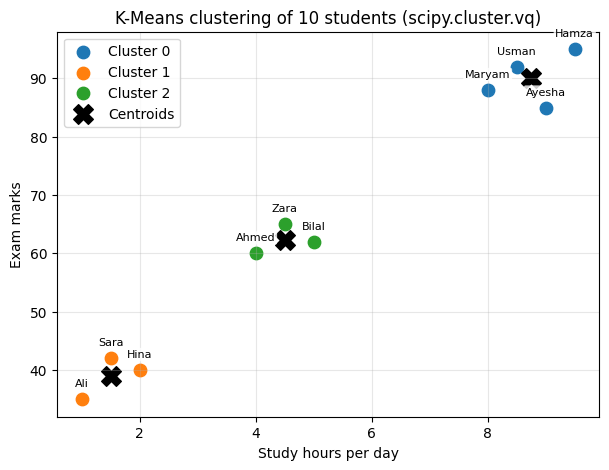

In [20]:
# ---- Visualization: scatter plot coloured by cluster ----
colors = ["tab:blue", "tab:orange", "tab:green"]

plt.figure(figsize=(7, 5))
for k in range(3):
    members = data[labels == k]
    plt.scatter(members[:, 0], members[:, 1], s=80, color=colors[k], label=f"Cluster {k}")

# draw centroids as black X marks
plt.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200, color="black", label="Centroids")

# write the student names next to the points
for name, row in zip(names, data):
    plt.annotate(name, (row[0], row[1]), textcoords="offset points", xytext=(0, 9),
                 ha="center", fontsize=8, zorder=5,
                 bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))

plt.xlabel("Study hours per day")
plt.ylabel("Exam marks")
plt.title("K-Means clustering of 10 students (scipy.cluster.vq)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## E. Visualization explanation
Each dot is one student. The x-axis is study hours and the y-axis is marks. Dots of the same colour belong to the same cluster. The black **X** marks are the centroids (the group averages). You can see three clear groups running from bottom-left (low hours, low marks) to top-right (high hours, high marks).

# 6. SciPy Constants (`scipy.constants`)

## A. Introduction
- **What is it?** A collection of **predefined scientific and mathematical constants** (and unit conversions) stored with accurate values.
- **Why use it?** We do not need to type or remember long numbers like `299792458` or `6.62607015e-34`, and we avoid typing mistakes.
- **Problem it solves:** Reliable, standard values for physics, chemistry and engineering formulas.
- **Real-world example:** A physics program that finds how far light travels in one minute.

## B. Important functions / values

| Name | Meaning | Value type |
|---|---|---|
| `constants.c` | Speed of light in vacuum | metres per second |
| `constants.G` | Gravitational constant | m³ kg⁻¹ s⁻² |
| `constants.h` | Planck constant | joule-seconds (J s) |
| `constants.N_A` | Avogadro constant | per mole (mol⁻¹) |
| `constants.pi` | The number π | no unit |
| `constants.physical_constants[name]` | A dictionary: gives `(value, unit, uncertainty)` for a constant name | — |

**Formulas in simple language**
- **Distance = speed × time.** Light travels at speed `c`, so in `t` seconds it covers `c × t` metres.
- **E = m c²** (Einstein): the energy `E` (joules) stored in a mass `m` (kilograms) equals the mass multiplied by the speed of light squared. Because `c` is huge, even a tiny mass holds a huge amount of energy.

In [21]:
from scipy import constants

# ---- 1. Display selected constants with their units ----
# physical_constants[...] returns (value, unit, uncertainty)
selected = {
    "Speed of light (c)":        "speed of light in vacuum",
    "Gravitational constant (G)": "Newtonian constant of gravitation",
    "Planck constant (h)":       "Planck constant",
    "Avogadro constant (N_A)":   "Avogadro constant",
}

print(f"{'Constant':<30}{'Value':>16}   Unit")
print("-" * 62)
for label, key in selected.items():
    value, unit, uncertainty = constants.physical_constants[key]
    print(f"{label:<30}{value:>16.6e}   {unit}")
print(f"{'Pi':<30}{constants.pi:>16.10f}   (no unit)")

# ---- 2. Distance travelled by light in a given time ----
time_seconds = 60                                  # one minute
distance_m = constants.c * time_seconds            # distance = speed x time
print(f"\nIn {time_seconds} seconds, light travels {distance_m:,.0f} m")
print(f"                        = {distance_m / 1000:,.0f} km")

# Extra check: how long does sunlight take to reach Earth?
sun_earth_m = constants.astronomical_unit          # average Sun-Earth distance (metres)
t_sun = sun_earth_m / constants.c                  # time = distance / speed
print(f"Sunlight reaches Earth in {t_sun:.1f} s  (= {t_sun / 60:.2f} minutes)")

# ---- 3. Energy from mass: E = m * c^2 ----
mass_kg = 1.0                                      # 1 kilogram
energy_j = mass_kg * constants.c ** 2
print(f"\nEnergy in {mass_kg} kg of mass: E = {energy_j:.6e} joules")
print(f"That equals about {energy_j / constants.ton_TNT:,.0f} tons of TNT")

# ---- 4. Using pi: area of a circle with radius 7 ----
radius = 7
print(f"\nArea of a circle (r = {radius}): {constants.pi * radius ** 2:.2f}")
print("Is constants.pi the same as np.pi?", constants.pi == np.pi)

Constant                                 Value   Unit
--------------------------------------------------------------
Speed of light (c)                2.997925e+08   m s^-1
Gravitational constant (G)        6.674300e-11   m^3 kg^-1 s^-2
Planck constant (h)               6.626070e-34   J Hz^-1
Avogadro constant (N_A)           6.022141e+23   mol^-1
Pi                                3.1415926536   (no unit)

In 60 seconds, light travels 17,987,547,480 m
                        = 17,987,547 km
Sunlight reaches Earth in 499.0 s  (= 8.32 minutes)

Energy in 1.0 kg of mass: E = 8.987552e+16 joules
That equals about 21,480,764 tons of TNT

Area of a circle (r = 7): 153.94
Is constants.pi the same as np.pi? True


## D. Output explanation
- **Constants table:** each value is read directly from SciPy, with its unit, for example `c = 2.997925e+08 m s^-1`.
- **Light in 60 seconds:** `299,792,458 m/s × 60 s = 17,987,547,480 m`, which is about **17,987,547 km**.
- **Sunlight check:** the Sun–Earth distance is about 1.496 × 10¹¹ m. Dividing by `c` gives about **499 seconds ≈ 8.32 minutes**, which matches the well-known fact that sunlight takes about 8 minutes to reach Earth. This confirms the calculation.
- **E = mc² for 1 kg:** `1 × (299,792,458)² = 8.987552 × 10¹⁶ joules`. That is roughly **21.5 million tons of TNT**, which shows how much energy is hidden in mass.
- **Pi:** `7 × 7 × π = 153.94`; SciPy's `pi` is the same value as NumPy's `pi`.

## E. Visualization
A graph is not needed for this module; clearly formatted printed output is the best way to show constants.

# 7. SciPy FFTPACK (`scipy.fftpack`)

## A. Introduction
**Basic ideas**
- **Signal:** a quantity that changes over time, like sound, a heartbeat (ECG), or a sensor reading.
- **Frequency:** how many times a pattern repeats in one second, measured in **hertz (Hz)**. A 5 Hz wave repeats 5 times per second.
- **Fourier Transform:** a mathematical method that breaks a signal into the simple sine waves (frequencies) it is made of.
- **FFT (Fast Fourier Transform):** a very fast algorithm to calculate the Fourier Transform on a computer.
- **Why is FFT useful?** It tells us *which frequencies are inside a signal*. Real-world example: a music app can find which musical notes are playing by looking at the frequencies in the sound.

*Analogy:* If a song is a smoothie, FFT tells you which fruits (frequencies) were mixed in and how much of each.

> **Note:** `scipy.fft` is the **modern recommended** FFT interface in SciPy. `scipy.fftpack` is an older (legacy) interface. We use `scipy.fftpack` here because it is part of the course requirement, and the code below also checks that both give the same result.

## B. Important functions

| Function | What it does | Important parameters |
|---|---|---|
| `fftpack.fft(x)` | Computes the FFT of the signal `x`; returns complex numbers | `x` = signal array |
| `fftpack.fftfreq(n, d)` | Gives the frequency (Hz) that belongs to each FFT output position ("bin") | `n` = number of samples, `d` = time between samples (1 / sampling rate) |
| `fftpack.ifft(X)` | Inverse FFT: rebuilds the original signal from the FFT result | `X` = FFT output |

In [22]:
from scipy import fftpack

# ---- 1. Make a signal with KNOWN frequencies ----
fs = 100                                  # sampling rate: 100 samples per second
t = np.arange(0, 1, 1 / fs)               # time points for 1 second (100 samples)
# 5 Hz wave with amplitude 1.0  +  12 Hz wave with amplitude 0.5
signal = 1.0 * np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 12 * t)

# ---- 2. Apply the FFT ----
fft_values = fftpack.fft(signal)                       # complex numbers
freqs = fftpack.fftfreq(len(signal), d=1 / fs)         # frequency of each bin (Hz)

# ---- 3. Convert to amplitude and keep only positive frequencies ----
amplitude = (2 / len(signal)) * np.abs(fft_values)     # size of each frequency
positive = freqs >= 0
freqs_pos = freqs[positive]
amp_pos = amplitude[positive]

# ---- 4. Find the strong frequencies (peaks) ----
peaks = freqs_pos[amp_pos > 0.1]
peak_amps = amp_pos[amp_pos > 0.1]
print("Number of samples:", len(signal))
print("Frequency step (resolution):", freqs_pos[1], "Hz")
for f, a in zip(peaks, peak_amps):
    print(f"Detected frequency = {f:.1f} Hz, amplitude = {a:.2f}")

# ---- 5. Checks ----
rebuilt = fftpack.ifft(fft_values).real
print("\nifft rebuilds the original signal:", np.allclose(rebuilt, signal))

from scipy import fft as modern_fft                    # the modern interface
print("scipy.fft gives the same FFT result:", np.allclose(fft_values, modern_fft.fft(signal)))

Number of samples: 100
Frequency step (resolution): 1.0 Hz
Detected frequency = 5.0 Hz, amplitude = 1.00
Detected frequency = 12.0 Hz, amplitude = 0.50

ifft rebuilds the original signal: True
scipy.fft gives the same FFT result: True


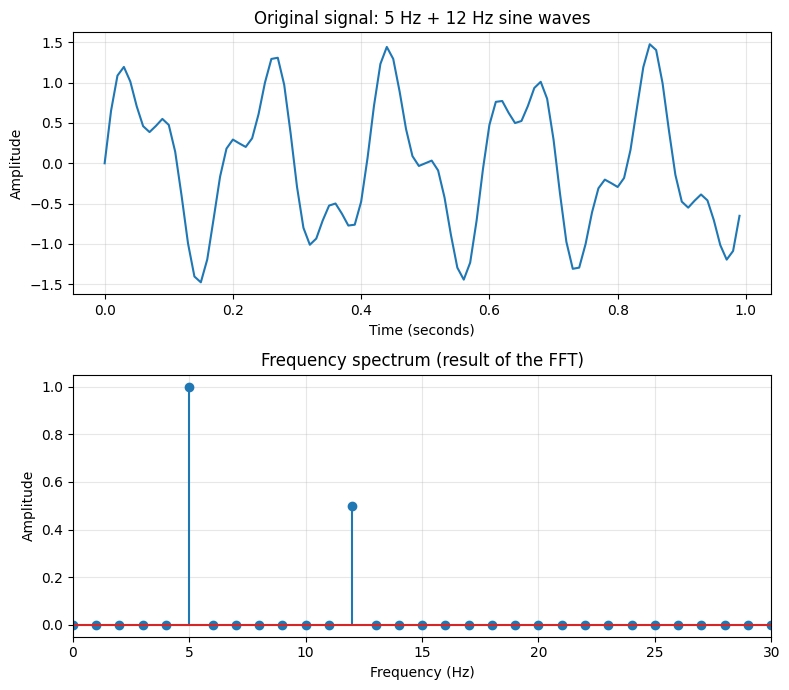

In [23]:
# ---- Visualization: signal in time, and its frequency spectrum ----
fig, axes = plt.subplots(2, 1, figsize=(8, 7))

# Top graph: the original signal
axes[0].plot(t, signal, color="tab:blue")
axes[0].set_title("Original signal: 5 Hz + 12 Hz sine waves")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(alpha=0.3)

# Bottom graph: the frequency spectrum from the FFT
axes[1].stem(freqs_pos, amp_pos)
axes[1].set_title("Frequency spectrum (result of the FFT)")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlim(0, 30)                 # zoom in on the interesting part
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## D. Output explanation
- We built the signal ourselves: a **5 Hz** wave (amplitude 1.0) plus a **12 Hz** wave (amplitude 0.5), sampled 100 times per second for 1 second, so there are **100 samples**.
- `fftfreq(100, d=0.01)` gives bins spaced **1 Hz** apart (0, 1, 2, ... 49 Hz, then negative frequencies).
- The FFT output is complex, so we take `abs()` to get the size of each frequency. Multiplying by `2/N` converts it into the real amplitude (we use only the positive half, because the negative half is a mirror image).
- Result: peaks appear exactly at **5 Hz (amplitude 1.0)** and **12 Hz (amplitude 0.5)**. These are the values we used to create the signal, so the result is easy to verify.
- `ifft` rebuilds the signal exactly, and `scipy.fft` gives identical numbers to `scipy.fftpack`.

## E. Visualization explanation
- **Top graph (time domain):** the wiggly line is the two waves added together. It is hard to see the two frequencies by eye.
- **Bottom graph (frequency domain):** the FFT makes it obvious. There are two tall spikes, one at 5 Hz (height 1.0) and one at 12 Hz (height 0.5). Everywhere else the height is zero.

## How the FFT identifies frequencies
The FFT compares the signal with sine waves of many frequencies. If the signal contains a frequency, the match is strong and a spike appears at that frequency. If it does not, the match is zero.

# 8. SciPy Interpolation (`scipy.interpolate`)

## A. Introduction
- **What is interpolation?** Estimating a value **between** known data points.
- **Why do we need it?** Real measurements are incomplete. A sensor might record the temperature only every 2 hours, but we may want to know the temperature at 5 o'clock.
- **Linear interpolation:** join two known points with a **straight line** and read the value on that line.
- **How does it estimate?** For a time `x` between two known points `(x1, y1)` and `(x2, y2)`:
  `y = y1 + (x − x1) × (y2 − y1) / (x2 − x1)`
- **Real-world example:** Temperature readings every 2 hours; estimate the temperature at the missing hour 5.

## B. Important functions

| Function | What it does | Important parameters |
|---|---|---|
| `interp1d(x, y, kind='linear')` | Builds a function that estimates `y` for any new `x` | `x`, `y` = known points; `kind` = `'linear'`, `'cubic'`, etc. |
| `CubicSpline(x, y)` | Builds a smooth curve (made of cubic polynomial pieces) through all the points | `x` must be increasing; `bc_type` = behaviour at the ends (default is fine) |

> **Legacy note:** `interp1d` is considered a **legacy interface**: it still works, but it is no longer being developed, and the SciPy documentation recommends newer tools such as `CubicSpline`, `make_interp_spline`, or NumPy's `np.interp` for new code. We use `interp1d` here to **learn** the idea, and `CubicSpline` as the modern approach.

In [24]:
from scipy.interpolate import interp1d, CubicSpline

# ---- 1. Known measurements: temperature every 2 hours ----
time_h = np.array([0, 2, 4, 6, 8, 10])          # hours
temp_c = np.array([15, 14, 19, 26, 24, 18])     # degrees Celsius
print("Known data points (hour, temperature):")
for h_, t_ in zip(time_h, temp_c):
    print(f"  {h_:>2} h -> {t_} C")

# ---- 2. Build the two interpolators ----
linear_func = interp1d(time_h, temp_c, kind="linear")   # legacy, good for learning
spline_func = CubicSpline(time_h, temp_c)                # modern, smooth curve

# ---- 3. Estimate the temperature at hour 5 (no measurement was taken) ----
new_time = 5
print(f"\nEstimated temperature at hour {new_time}:")
print(f"  Linear interpolation : {float(linear_func(new_time)):.2f} C")
print(f"  Cubic spline         : {float(spline_func(new_time)):.2f} C")

# ---- 4. Verify the linear result by hand using the formula ----
x1, y1, x2, y2 = 4, 19, 6, 26        # the two neighbouring known points
by_hand = y1 + (new_time - x1) * (y2 - y1) / (x2 - x1)
print(f"  Linear by hand       : {by_hand:.2f} C   (matches interp1d)")
print(f"  NumPy np.interp      : {float(np.interp(new_time, time_h, temp_c)):.2f} C")

# Another missing hour
print(f"\nAt hour 3 -> linear {float(linear_func(3)):.2f} C, spline {float(spline_func(3)):.2f} C")

Known data points (hour, temperature):
   0 h -> 15 C
   2 h -> 14 C
   4 h -> 19 C
   6 h -> 26 C
   8 h -> 24 C
  10 h -> 18 C

Estimated temperature at hour 5:
  Linear interpolation : 22.50 C
  Cubic spline         : 23.05 C
  Linear by hand       : 22.50 C   (matches interp1d)
  NumPy np.interp      : 22.50 C

At hour 3 -> linear 16.50 C, spline 15.82 C


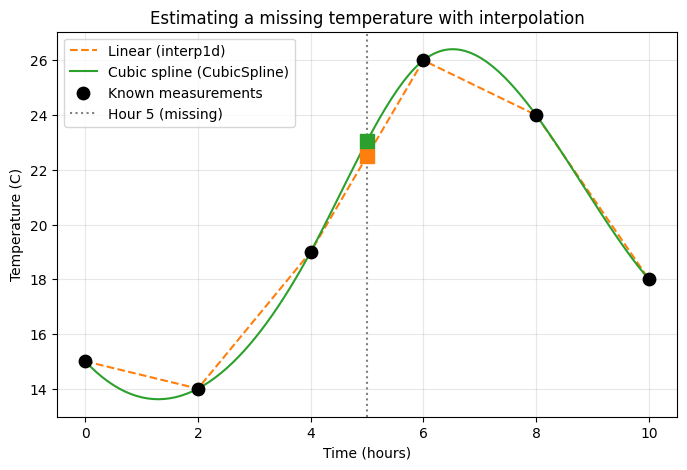

In [25]:
# ---- Visualization: known points and both interpolation curves ----
t_fine = np.linspace(0, 10, 200)        # many time points for smooth lines

plt.figure(figsize=(8, 5))
plt.plot(t_fine, linear_func(t_fine), "--", color="tab:orange", label="Linear (interp1d)")
plt.plot(t_fine, spline_func(t_fine), "-", color="tab:green", label="Cubic spline (CubicSpline)")
plt.scatter(time_h, temp_c, s=80, color="black", zorder=3, label="Known measurements")

# mark the estimated values at hour 5
plt.scatter([5], [float(linear_func(5))], marker="s", s=90, color="tab:orange", zorder=4)
plt.scatter([5], [float(spline_func(5))], marker="s", s=90, color="tab:green", zorder=4)
plt.axvline(5, color="gray", linestyle=":", label="Hour 5 (missing)")

plt.xlabel("Time (hours)")
plt.ylabel("Temperature (C)")
plt.title("Estimating a missing temperature with interpolation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## D. Output explanation
- **Known data:** six measurements, one every 2 hours.
- **Linear at hour 5:** hour 5 lies between hour 4 (19 °C) and hour 6 (26 °C). It is exactly halfway, so the estimate is `19 + (5 − 4) × (26 − 19) / (6 − 4) = 22.5 °C`. The hand calculation, `interp1d` and `np.interp` all give **22.50 °C**.
- **Cubic spline at hour 5:** the smooth curve gives about **23.05 °C**. It is a little higher because the spline follows the way the temperature is rising and then levels off, instead of using a straight line.
- **Hour 3:** linear gives **16.50 °C**, the spline gives about **15.82 °C**.
- Both methods pass **exactly through** every known point; they only differ in how they estimate the values in between.

## E. Visualization explanation
The black dots are the real measurements. The orange dashed line connects them with straight segments (linear). The green line is the smooth cubic-spline curve. The squares at hour 5 are the two estimates, and the dotted vertical line marks the missing hour.

**Which should I use?** Linear is simple and safe. A cubic spline looks smoother and is better when the real data changes smoothly, but it can slightly overshoot between points when data changes suddenly.

# 9. SciPy Linear Algebra (`scipy.linalg`)

## A. Introduction
- **Linear algebra** is the branch of mathematics that studies **vectors, matrices and linear equations**.
- **Matrix:** a rectangular table of numbers arranged in rows and columns, for example a 2×2 matrix has 2 rows and 2 columns.
- **Why are matrices important?** In programming and AI, almost everything is stored as matrices: images (pixel tables), data sets (rows and columns), and the weights inside neural networks.
- **Problem it solves:** solving systems of equations, finding how a matrix stretches space (eigenvalues), checking if a matrix can be reversed (determinant / inverse).
- **Real-world example:** two shops sell pens and notebooks at different total prices; linear algebra finds the price of one pen and one notebook.

## B. Important functions

| Function | What it does | Important parameters |
|---|---|---|
| `linalg.det(A)` | Determinant of a square matrix. If it is 0, the matrix has **no inverse** | `A` = square matrix |
| `linalg.inv(A)` | Inverse matrix: `A × A⁻¹ = I` (identity matrix) | `A` = square matrix with non-zero determinant |
| `linalg.solve(A, b)` | Solves the system `A x = b` | `A` = coefficient matrix, `b` = right-hand side |
| `linalg.eig(A)` | Returns `(eigenvalues, eigenvectors)`. An eigenvector keeps its direction when multiplied by `A` and is only scaled by its eigenvalue | `A` = square matrix |

**Example system:**
`2x + y = 5`
`x + 3y = 6`
In matrix form: `A = [[2, 1], [1, 3]]`, `b = [5, 6]`.

> `solve()` is generally **preferred over calculating the inverse** (`inv(A) @ b`) when solving equations. It is faster and numerically more accurate. We calculate the inverse here for learning only.

In [26]:
from scipy import linalg

# ---- Matrix A and right-hand side b for:  2x + y = 5  and  x + 3y = 6 ----
A = np.array([[2, 1],
              [1, 3]])
b = np.array([5, 6])
print("Matrix A:\n", A)

# ---- 1. Determinant ----
det_A = linalg.det(A)
print("\n1) Determinant of A:", det_A)            # 2*3 - 1*1 = 5

# ---- 2. Inverse ----
inv_A = linalg.inv(A)
print("\n2) Inverse of A:\n", inv_A)
print("   A @ inv(A) is the identity matrix:", np.allclose(A @ inv_A, np.eye(2)))

# ---- 3. Solve the simultaneous equations ----
solution = linalg.solve(A, b)
x, y = solution
print(f"\n3) Solution with solve(): x = {x:.2f}, y = {y:.2f}")
print("   Same answer using inv(A) @ b:", np.allclose(solution, inv_A @ b))

# Verify by substituting x and y back into the original equations
# (round() hides tiny floating-point noise such as 4.999999999999999)
print("   Check equation 1: 2x + y  =", round(2 * x + y, 6), "(should be 5)")
print("   Check equation 2: x + 3y  =", round(x + 3 * y, 6), "(should be 6)")

# ---- 4. Eigenvalues and eigenvectors ----
eigenvalues, eigenvectors = linalg.eig(A)
eigenvalues = eigenvalues.real                    # A is symmetric, so values are real
print("\n4) Eigenvalues:", eigenvalues.round(4))
print("   Eigenvectors (each column is one eigenvector):\n", eigenvectors.round(4))

# Verify: A @ v should equal (eigenvalue * v) for each eigenvector v
for i in range(2):
    v = eigenvectors[:, i]
    print(f"   Check eigenvector {i}: A@v == lambda*v ->", np.allclose(A @ v, eigenvalues[i] * v))

Matrix A:
 [[2 1]
 [1 3]]

1) Determinant of A: 5.0

2) Inverse of A:
 [[ 0.6 -0.2]
 [-0.2  0.4]]
   A @ inv(A) is the identity matrix: True

3) Solution with solve(): x = 1.80, y = 1.40
   Same answer using inv(A) @ b: True
   Check equation 1: 2x + y  = 5.0 (should be 5)
   Check equation 2: x + 3y  = 6.0 (should be 6)

4) Eigenvalues: [1.382 3.618]
   Eigenvectors (each column is one eigenvector):
 [[-0.8507 -0.5257]
 [ 0.5257 -0.8507]]
   Check eigenvector 0: A@v == lambda*v -> True
   Check eigenvector 1: A@v == lambda*v -> True


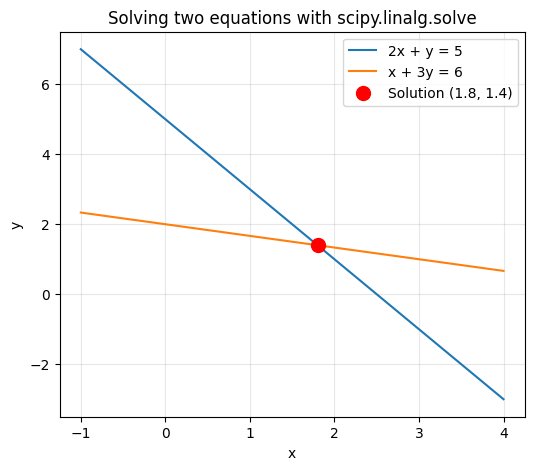

In [27]:
# ---- Visualization: the two equations as lines; the solution is where they cross ----
xs = np.linspace(-1, 4, 100)
line1 = 5 - 2 * xs            # from 2x + y = 5  ->  y = 5 - 2x
line2 = (6 - xs) / 3          # from x + 3y = 6  ->  y = (6 - x) / 3

plt.figure(figsize=(6, 5))
plt.plot(xs, line1, label="2x + y = 5")
plt.plot(xs, line2, label="x + 3y = 6")
plt.scatter([x], [y], color="red", s=100, zorder=3, label=f"Solution ({x:.1f}, {y:.1f})")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Solving two equations with scipy.linalg.solve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## D. Output explanation
- **Determinant:** for a 2×2 matrix `[[a, b], [c, d]]` it is `a×d − b×c`, so `2×3 − 1×1 = 5`. Because it is not zero, the matrix can be inverted.
- **Inverse:** the formula gives `(1/5) × [[3, −1], [−1, 2]] = [[0.6, −0.2], [−0.2, 0.4]]`. Multiplying `A` by it gives the identity matrix (the code confirms this).
- **Solution:** `x = 1.8` and `y = 1.4`.
  **Verification by substitution:** `2(1.8) + 1.4 = 3.6 + 1.4 = 5` ✔ and `1.8 + 3(1.4) = 1.8 + 4.2 = 6` ✔. (Computers store decimals approximately, so a raw result can look like `4.999999999999999`; rounding shows it is 5.)
- **Eigenvalues:** the two eigenvalues are `(5 ± √5) / 2`, that is about **1.382** and **3.618**. The code verifies that `A·v = λ·v` for both eigenvectors (the order in which they are listed can differ between versions).

## E. Visualization explanation
Each equation is a straight line. The solution of the two equations is the **one point that lies on both lines**, which is where they cross: the red dot at (1.8, 1.4).

# 10. SciPy NDIMAGE (`scipy.ndimage`)

## A. Introduction
- **Digital image processing:** using a computer to change or analyse an image, for example to blur it, rotate it or find edges.
- **Pixel:** one tiny square of an image. A grayscale image is a table (NumPy array) of pixel values, for example `0` = black and `1` = white.
- **Image filtering:** replacing each pixel with a new value calculated from its neighbouring pixels.
- **Gaussian blur:** a filter that replaces each pixel with a weighted average of its neighbours, so the image becomes smooth and soft. The `sigma` value controls how strong the blur is.
- **Image rotation:** turning the image by a given angle.
- **Edge detection (Sobel):** edges are places where brightness changes quickly. The Sobel filter measures this change.
- **Real-world example:** a phone camera app blurs a background or a medical program highlights the edges of an organ in a scan.

## B. Important functions

| Function | What it does | Important parameters |
|---|---|---|
| `ndimage.gaussian_filter(img, sigma)` | Gaussian blur | `sigma` = blur strength (bigger = blurrier) |
| `ndimage.rotate(img, angle)` | Rotates the image | `angle` = degrees; `reshape=False` keeps the same image size |
| `ndimage.sobel(img, axis)` | Edge detection: measures brightness change along one direction | `axis` = 0 (up-down changes) or 1 (left-right changes) |

In [28]:
from scipy import ndimage

# ---- 1. Create a simple 64 x 64 grayscale image (no files needed) ----
image = np.zeros((64, 64))           # all black (0)
image[15:45, 20:40] = 1.0            # a tall white rectangle
image[50:58, 5:13] = 0.6             # a small gray square
print("Image shape:", image.shape, "| min =", image.min(), "| max =", image.max())

# ---- 2. Gaussian blur ----
blurred = ndimage.gaussian_filter(image, sigma=2)

# ---- 3. Rotation by 30 degrees (reshape=False keeps the 64 x 64 size) ----
rotated = ndimage.rotate(image, angle=30, reshape=False)

# ---- 4. Edge detection with the Sobel filter ----
edges_vertical = ndimage.sobel(image, axis=0)      # brightness change top-to-bottom
edges_horizontal = ndimage.sobel(image, axis=1)    # brightness change left-to-right
edges = np.hypot(edges_horizontal, edges_vertical) # combine both into one edge map

# ---- Some numbers to understand the results ----
print("\nTotal brightness  original:", round(image.sum(), 2), "| blurred:", round(blurred.sum(), 2))
print("Rotated image shape:", rotated.shape)

# Blur makes edges softer, so the strongest Sobel edge of the blurred image is weaker
edges_of_blurred = np.hypot(ndimage.sobel(blurred, axis=0), ndimage.sobel(blurred, axis=1))
print("Strongest edge value  original:", round(edges.max(), 2),
      "| blurred:", round(edges_of_blurred.max(), 2))

Image shape: (64, 64) | min = 0.0 | max = 1.0

Total brightness  original: 638.4 | blurred: 638.4
Rotated image shape: (64, 64)
Strongest edge value  original: 4.24 | blurred: 1.5


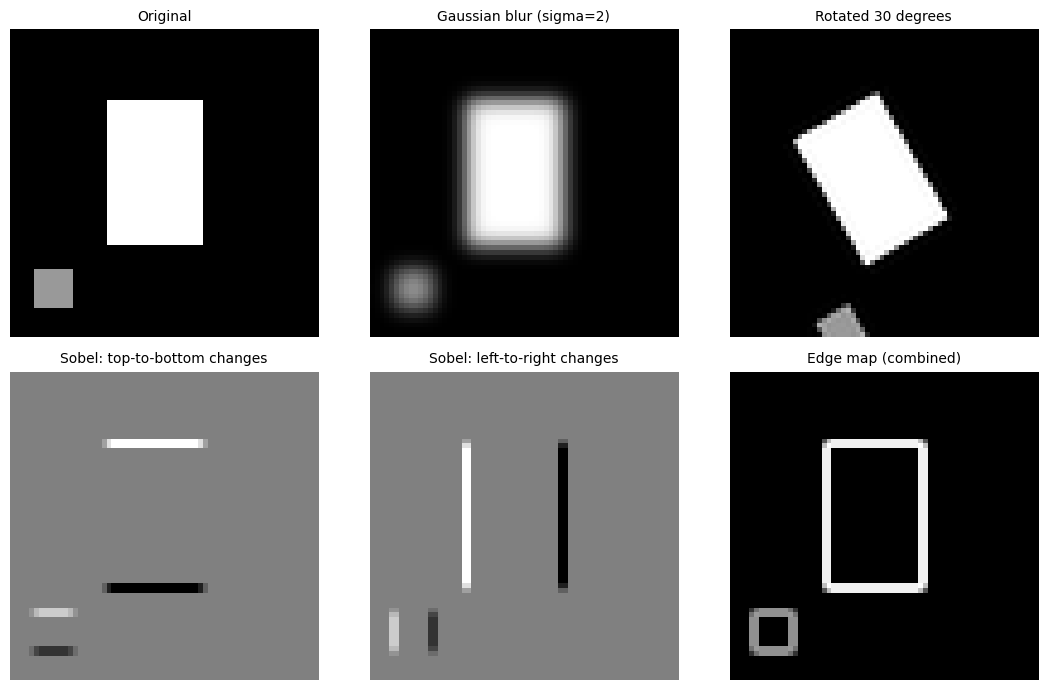

In [29]:
# ---- 5. Display the original and all processed images ----
titles = ["Original", "Gaussian blur (sigma=2)", "Rotated 30 degrees",
          "Sobel: top-to-bottom changes", "Sobel: left-to-right changes", "Edge map (combined)"]
images = [image, blurred, rotated, edges_vertical, edges_horizontal, edges]

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for i, (ax, img, title) in enumerate(zip(axes.ravel(), images, titles)):
    if i < 3:
        # first three images: fixed brightness range 0 (black) to 1 (white) so they are comparable
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    else:
        # edge images: let Matplotlib choose the range (gray = no change)
        ax.imshow(img, cmap="gray")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## D. Output explanation
- **Original:** a 64 × 64 array. Pixel values are `0.0` (black), `0.6` (gray) and `1.0` (white).
- **Blurred:** the blur spreads brightness to neighbouring pixels. The total brightness stays the same (`638.4` before and after), but the sharp edges become soft. We can measure this: the strongest edge value drops from **4.24** in the original to **1.5** in the blurred image.
- **Rotated:** the whole picture turns by 30°. Because we used `reshape=False`, the shape is still 64 × 64, so any part of the picture that moves outside the frame is cut off (look at the gray square at the bottom), and the new empty areas are filled with `0` (black).
- **Sobel:** the output is `0` in flat areas (all black or all white) and large only at the borders of the shapes. In the two directional images, `0` is shown as mid-gray, a change from dark to bright is shown as white, and a change from bright to dark is shown as black. The two directional versions find horizontal and vertical borders; combining them with `np.hypot` shows all the edges.

## E. Visualization explanation
The top-left image is the original. Top-middle shows the soft, blurred shapes. Top-right shows the tilted shapes. The bottom row shows edge detection: the vertical-change image highlights the top and bottom edges of the shapes, the horizontal-change image highlights the left and right edges, and the last image combines them into an outline of the shapes.

# 11. Summary Table

| SciPy Subpackage | Main Purpose | Important Functions | Practical Example |
|---|---|---|---|
| **Cluster** (`scipy.cluster.vq`) | Group similar data automatically | `whiten()`, `kmeans()`, `vq()` | K-Means grouping of 10 students by study hours and marks into 3 clusters |
| **Constants** (`scipy.constants`) | Provide accurate scientific and mathematical constants | `c`, `G`, `h`, `N_A`, `pi`, `physical_constants` | Distance light travels in 60 s; energy from 1 kg using E = mc² |
| **FFTPACK** (`scipy.fftpack`) | Find the frequencies inside a signal | `fft()`, `fftfreq()`, `ifft()` | FFT of a 5 Hz + 12 Hz signal; spectrum shows peaks at 5 and 12 Hz |
| **Interpolate** (`scipy.interpolate`) | Estimate values between known data points | `interp1d()` (legacy), `CubicSpline()` | Estimate the missing temperature at hour 5 (22.5 °C linear, about 23.05 °C spline) |
| **Linalg** (`scipy.linalg`) | Matrix operations and solving equations | `det()`, `inv()`, `solve()`, `eig()` | Solve 2x + y = 5 and x + 3y = 6, giving x = 1.8, y = 1.4 |
| **NDIMAGE** (`scipy.ndimage`) | Process and filter images | `gaussian_filter()`, `rotate()`, `sobel()` | Blur, rotate and edge-detect a 64×64 NumPy image |

# 12. Real-World Applications

| Subpackage | Where it is used in real life |
|---|---|
| **Cluster** | Grouping customers by buying habits, grouping students by performance, compressing colours in images |
| **Constants** | Physics and chemistry software, engineering calculators, space-science programs |
| **FFTPACK / FFT** | Music and voice analysis, noise removal, mobile and Wi-Fi communication, ECG and EEG analysis |
| **Interpolate** | Filling missing sensor or weather readings, smooth animation paths, resizing data and maps |
| **Linalg** | Machine learning and neural networks, computer graphics, engineering simulations, recommendation systems |
| **NDIMAGE** | Photo filters, medical scans (X-ray, MRI), face and object detection pre-processing, satellite images |

**For Software Engineering, AI and Data Science students:** these tools appear in real projects, such as audio apps, image apps, data-cleaning pipelines and machine-learning models.

# 13. Conclusion

In this practical we used Google Colab to study six SciPy subpackages with small, reproducible examples:

1. **Cluster:** grouped 10 students into 3 clusters with `whiten()`, `kmeans()` and `vq()`.
2. **Constants:** used exact scientific constants to calculate the distance travelled by light and the energy in mass.
3. **FFTPACK:** used the FFT to recover the 5 Hz and 12 Hz frequencies hidden in a signal.
4. **Interpolate:** estimated a missing temperature with linear and cubic-spline interpolation.
5. **Linalg:** found the determinant, inverse, solution and eigenvalues of a 2×2 system and verified the answers.
6. **NDIMAGE:** blurred, rotated and edge-detected an image created with NumPy.

SciPy builds on NumPy to give us fast, trusted scientific tools, and it is an important library for Software Engineering, AI and Data Science.